# Step 1 — Environment and Dataset Inspection

In [1]:
import os
import sys
import glob
import psutil
import pandas as pd

# 1. Check Python environment
print("Python Version:", sys.version.split()[0])
print("Pandas Version:", pd.__version__)

# 2. Check available RAM
memory = psutil.virtual_memory()

print("\n--- System Memory ---")
print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM Usage: {memory.percent}%")

# 3. Specify the dataset folder
DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

# 4. Locate the four CSV files
expected_files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

print("\n--- Dataset File Inspection ---")

for name in expected_files:
    path = os.path.join(DATASET_DIR, name)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"{name}: Found ({size_mb:.2f} MB)")

        # Read only 5 rows to minimize memory usage
        sample = pd.read_csv(path, nrows=5, low_memory=False)

        print("Columns:", sample.columns.tolist())
        print("Sample shape:", sample.shape)
        print(sample.head(2))

        del sample
    else:
        print(f"{name}: Not found")

print("\nStep 1 completed. No model training performed.")


Python Version: 3.13.9
Pandas Version: 2.3.3

--- System Memory ---
Total RAM: 15.34 GB
Available RAM: 4.39 GB
RAM Usage: 71.4%

--- Dataset File Inspection ---
UNSW-NB15_1.csv: Found (161.15 MB)
Columns: ['59.166.0.0', '1390', '149.171.126.6', '53', 'udp', 'CON', '0.001055', '132', '164', '31', '29', '0', '0.1', 'dns', '500473.9375', '621800.9375', '2', '2.1', '0.2', '0.3', '0.4', '0.5', '66', '82', '0.6', '0.7', '0.8', '0.9', '1421927414', '1421927414.1', '0.017', '0.013', '0.10', '0.11', '0.12', '0.13', '0.14', '0.15', '0.16', '0.17', '3', '7', '1', '3.1', '1.1', '1.2', '1.3', 'Unnamed: 47', '0.18']
Sample shape: (5, 49)
   59.166.0.0   1390  149.171.126.6    53  udp  CON  0.001055  132  164  31  \
0  59.166.0.0  33661  149.171.126.9  1024  udp  CON  0.036133  528  304  31   
1  59.166.0.6   1464  149.171.126.7    53  udp  CON  0.001119  146  178  31   

   ...  0.17   3  7  1  3.1  1.1  1.2  1.3  Unnamed: 47  0.18  
0  ...     0   2  4  2    3    1    1    2          NaN     0  
1 

In [2]:

# STEP 1A: Verify Raw CSV Structure

import os
import pandas as pd

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

for filename in files:
    path = os.path.join(DATASET_DIR, filename)

    print(f"\n--- {filename} ---")

    # Raw files do not have a header row
    sample = pd.read_csv(
        path,
        header=None,
        nrows=3,
        low_memory=False
    )

    print("Sample shape:", sample.shape)
    print("First 3 records:")
    print(sample.iloc[:, :8].to_string(index=False, header=False))
    print("Last 5 columns:")
    print(sample.iloc[:, -5:].to_string(index=False, header=False))

    del sample

print("\nRaw CSV inspection completed.")



--- UNSW-NB15_1.csv ---
Sample shape: (3, 49)
First 3 records:
59.166.0.0  1390 149.171.126.6   53 udp CON 0.001055 132
59.166.0.0 33661 149.171.126.9 1024 udp CON 0.036133 528
59.166.0.6  1464 149.171.126.7   53 udp CON 0.001119 146
Last 5 columns:
1 1 1 NaN 0
1 1 2 NaN 0
2 1 1 NaN 0

--- UNSW-NB15_2.csv ---
Sample shape: (3, 49)
First 3 records:
59.166.0.0  6055 149.171.126.5 54145 tcp FIN 0.072974 4238
59.166.0.0  7832 149.171.126.3  5607 tcp FIN 0.144951 5174
59.166.0.8 11397 149.171.126.6    21 tcp FIN 0.116107 2934
Last 5 columns:
1 1 2 NaN 0
1 1 2 NaN 0
1 1 4 NaN 0

--- UNSW-NB15_3.csv ---
Sample shape: (3, 49)
First 3 records:
59.166.0.1 18247 149.171.126.4  7662 tcp FIN 0.119596 4550
59.166.0.3 54771 149.171.126.2 27709 tcp FIN 0.650574 8928
59.166.0.8 13289 149.171.126.9  5190 tcp FIN 0.007980 2158
Last 5 columns:
1 1 2 NaN 0
1 1 4 NaN 0
1 1 3 NaN 0

--- UNSW-NB15_4.csv ---
Sample shape: (3, 49)
First 3 records:
59.166.0.9 7045 149.171.126.7 25 tcp FIN 0.201886 37552
59.166.

# Step 2 — Feature Names and Dataset Structure

In [3]:

# STEP 2: Inspect Official Feature Names

import os
import pandas as pd

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

FEATURE_FILE = os.path.join(
    DATASET_DIR,
    "UNSW-NB15_features.csv"
)

if not os.path.exists(FEATURE_FILE):
    print("Feature file not found. Check its filename and folder.")
else:
    features = pd.read_csv(FEATURE_FILE, encoding="latin1")

    print("Feature file shape:", features.shape)
    print("\nFeature file columns:")
    print(features.columns.tolist())

    print("\nFirst 15 feature definitions:")
    print(features.head(15).to_string(index=False))

    print("\nLast 10 feature definitions:")
    print(features.tail(10).to_string(index=False))


Feature file not found. Check its filename and folder.


In [4]:

# STEP 2: Assign Official UNSW-NB15 Feature Names

import os
import pandas as pd

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

# Official 49-column schema for the raw UNSW-NB15 files
column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

print("Number of expected columns:", len(column_names))

for filename in files:
    path = os.path.join(DATASET_DIR, filename)

    print(f"\n--- {filename} ---")

    # Read only 5 rows; do not load the full file
    sample = pd.read_csv(
        path,
        header=None,
        names=column_names,
        nrows=5,
        low_memory=False
    )

    print("Sample shape:", sample.shape)
    print("Feature names:", sample.columns.tolist())
    print("\nAttack category and label:")
    print(sample[["attack_cat", "label"]].to_string(index=False))

    del sample

print("\nStep 2 inspection completed.")


Number of expected columns: 49

--- UNSW-NB15_1.csv ---
Sample shape: (5, 49)
Feature names: ['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']

Attack category and label:
 attack_cat  label
        NaN      0
        NaN      0
        NaN      0
        NaN      0
        NaN      0

--- UNSW-NB15_2.csv ---
Sample shape: (5, 49)
Feature names: ['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload',

# Step 3 — Inspect Attack Labels and Missing Values

In [5]:
import os
import pandas as pd

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

for filename in files:
    path = os.path.join(DATASET_DIR, filename)

    df = pd.read_csv(
        path,
        header=None,
        names=column_names,
        nrows=10000,
        low_memory=False
    )

    print(f"\n--- {filename} ---")
    print("Rows inspected:", len(df))

    print("\nBinary label counts:")
    print(df["label"].value_counts(dropna=False))

    print("\nAttack category counts:")
    print(df["attack_cat"].value_counts(dropna=False).head(15))

    print("\nMissing values in label columns:")
    print(df[["attack_cat", "label"]].isna().sum())

    del df

print("\nStep 3 completed.")



--- UNSW-NB15_1.csv ---
Rows inspected: 10000

Binary label counts:
label
0    9327
1     673
Name: count, dtype: int64

Attack category counts:
attack_cat
NaN               9327
Exploits           259
 Fuzzers           231
Reconnaissance      99
DoS                 35
Generic             32
Shellcode           15
Worms                2
Name: count, dtype: int64

Missing values in label columns:
attack_cat    9327
label            0
dtype: int64

--- UNSW-NB15_2.csv ---
Rows inspected: 10000

Binary label counts:
label
0    10000
Name: count, dtype: int64

Attack category counts:
attack_cat
NaN    10000
Name: count, dtype: int64

Missing values in label columns:
attack_cat    10000
label             0
dtype: int64

--- UNSW-NB15_3.csv ---
Rows inspected: 10000

Binary label counts:
label
0    7534
1    2466
Name: count, dtype: int64

Attack category counts:
attack_cat
NaN                 7534
Generic             2090
 Fuzzers             137
Exploits             136
 Reconnaissance  

# Step 4 — Full Dataset Attack Distribution Analysis

In [6]:
import os
import pandas as pd
from collections import Counter

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

label_counts = Counter()
attack_counts = Counter()
total_rows = 0

for filename in files:
    path = os.path.join(DATASET_DIR, filename)

    print(f"\nProcessing: {filename}")
    file_rows = 0

    for chunk in pd.read_csv(
        path,
        header=None,
        names=column_names,
        chunksize=50000,
        low_memory=False
    ):
        total_rows += len(chunk)
        file_rows += len(chunk)

        # Count normal and attack labels
        label_counts.update(
            chunk["label"].value_counts().to_dict()
        )

        # Normalize attack names and count non-missing categories
        categories = (
            chunk["attack_cat"]
            .astype("string")
            .str.strip()
        )

        categories = categories[
            categories.notna() & categories.ne("")
        ]

        attack_counts.update(categories.value_counts().to_dict())

        del chunk

    print(f"Rows processed: {file_rows:,}")

print("\n--- FULL DATASET SUMMARY ---")
print(f"Total records: {total_rows:,}")

print("\nBinary label distribution:")
for label, count in sorted(label_counts.items()):
    print(f"Label {label}: {count:,}")

print("\nAttack category distribution:")
for category, count in attack_counts.most_common():
    print(f"{category}: {count:,}")

print("\nStep 4 completed.")



Processing: UNSW-NB15_1.csv
Rows processed: 700,001

Processing: UNSW-NB15_2.csv
Rows processed: 700,001

Processing: UNSW-NB15_3.csv
Rows processed: 700,001

Processing: UNSW-NB15_4.csv
Rows processed: 440,044

--- FULL DATASET SUMMARY ---
Total records: 2,540,047

Binary label distribution:
Label 0: 2,218,764
Label 1: 321,283

Attack category distribution:
Generic: 215,481
Exploits: 44,525
Fuzzers: 24,246
DoS: 16,353
Reconnaissance: 13,987
Analysis: 2,677
Backdoor: 1,795
Shellcode: 1,511
Backdoors: 534
Worms: 174

Step 4 completed.


# Step 5 — Data Quality and Attack-Label Verification

In [7]:
import os
import pandas as pd

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

total_rows = 0

for filename in files:
    path = os.path.join(DATASET_DIR, filename)

    # Count physical data rows without loading them into RAM
    with open(path, "rb") as f:
        row_count = sum(1 for _ in f)

    total_rows += row_count
    print(f"{filename}: {row_count:,} rows")

print(f"\nTotal physical rows: {total_rows:,}")

print("\n--- Distinct Attack Labels ---")

for filename in files:
    path = os.path.join(DATASET_DIR, filename)

    for chunk in pd.read_csv(
        path,
        header=None,
        names=column_names,
        usecols=[47, 48],
        chunksize=50000,
        low_memory=False
    ):
        labels = (
            chunk["attack_cat"]
            .dropna()
            .astype(str)
            .str.strip()
        )

        # Display labels only; do not merge or alter categories
        unique_labels = sorted(labels.unique().tolist())

        print(f"{filename}: {unique_labels}")
        break

print("\nStep 5 inspection completed.")


UNSW-NB15_1.csv: 700,001 rows
UNSW-NB15_2.csv: 700,001 rows
UNSW-NB15_3.csv: 700,001 rows
UNSW-NB15_4.csv: 440,044 rows

Total physical rows: 2,540,047

--- Distinct Attack Labels ---
UNSW-NB15_1.csv: ['Backdoors', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
UNSW-NB15_2.csv: []
UNSW-NB15_3.csv: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
UNSW-NB15_4.csv: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']

Step 5 inspection completed.


# Step 6 — Verify Attack Labels Across All Files

In [8]:
import os
import pandas as pd
from collections import Counter

DATASET_DIR = r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

attack_counts = Counter()
missing_attack_labels = 0
total_rows = 0

for filename in files:
    path = os.path.join(DATASET_DIR, filename)
    print("Processing:", filename)

    for chunk in pd.read_csv(
        path,
        header=None,
        names=column_names,
        usecols=["attack_cat", "label"],
        chunksize=50000,
        low_memory=False
    ):
        total_rows += len(chunk)

        categories = chunk["attack_cat"].astype("string").str.strip()
        missing_attack_labels += categories.isna().sum()

        valid = categories.notna() & categories.ne("")
        attack_counts.update(categories[valid].value_counts().to_dict())

        del chunk

print("\nTotal records processed:", f"{total_rows:,}")
print("Missing attack category labels:", f"{missing_attack_labels:,}")

print("\nAttack category counts:")
for category, count in attack_counts.most_common():
    print(f"{category}: {count:,}")

print("\nStep 6 completed.")


Processing: UNSW-NB15_1.csv
Processing: UNSW-NB15_2.csv
Processing: UNSW-NB15_3.csv
Processing: UNSW-NB15_4.csv

Total records processed: 2,540,047
Missing attack category labels: 2,218,764

Attack category counts:
Generic: 215,481
Exploits: 44,525
Fuzzers: 24,246
DoS: 16,353
Reconnaissance: 13,987
Analysis: 2,677
Backdoor: 1,795
Shellcode: 1,511
Backdoors: 534
Worms: 174

Step 6 completed.


# Step 7 — Prepare the Attack-Label Summary

In [9]:
import pandas as pd

attack_counts = {
    "Generic": 215481,
    "Exploits": 44525,
    "Fuzzers": 24246,
    "DoS": 16353,
    "Reconnaissance": 13987,
    "Analysis": 2677,
    "Backdoor": 1795,
    "Shellcode": 1511,
    "Backdoors": 534,
    "Worms": 174
}

summary = pd.DataFrame(
    list(attack_counts.items()),
    columns=["Attack Category", "Number of Records"]
)

summary = summary.sort_values(
    by="Number of Records",
    ascending=True
).reset_index(drop=True)

summary["Percentage of Attack Records"] = (
    summary["Number of Records"]
    / summary["Number of Records"].sum()
    * 100
).round(3)

print("Attack Category Summary (Rare to Common):\n")
print(summary.to_string(index=False))

print("\nTotal attack-category records:",
      summary["Number of Records"].sum())

print("\nRarest listed category:",
      summary.iloc[0]["Attack Category"])

print("Rarest category count:",
      summary.iloc[0]["Number of Records"])


Attack Category Summary (Rare to Common):

Attack Category  Number of Records  Percentage of Attack Records
          Worms                174                         0.054
      Backdoors                534                         0.166
      Shellcode               1511                         0.470
       Backdoor               1795                         0.559
       Analysis               2677                         0.833
 Reconnaissance              13987                         4.353
            DoS              16353                         5.090
        Fuzzers              24246                         7.547
       Exploits              44525                        13.858
        Generic             215481                        67.069

Total attack-category records: 321283

Rarest listed category: Worms
Rarest category count: 174


# Step 8: Verify attack labels before training

In [10]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)

files = [
    DATA_DIR / "UNSW-NB15_1.csv",
    DATA_DIR / "UNSW-NB15_2.csv",
    DATA_DIR / "UNSW-NB15_3.csv",
    DATA_DIR / "UNSW-NB15_4.csv"
]

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

category_counts = {}
label_category_check = {}

for file in files:
    for chunk in pd.read_csv(
        file,
        header=None,
        names=column_names,
        chunksize=50000,
        low_memory=False
    ):
        categories = (
            chunk["attack_cat"]
            .astype("string")
            .str.strip()
        )

        counts = categories.value_counts(dropna=True)
        for category, count in counts.items():
            category_counts[category] = (
                category_counts.get(category, 0) + int(count)
            )

        labels = pd.to_numeric(chunk["label"], errors="coerce")

        # Normal records should normally have a missing attack category.
        normal_with_category = (
            (labels == 0) & categories.notna()
        ).sum()

        attack_without_category = (
            (labels == 1) & categories.isna()
        ).sum()

        label_category_check["normal_with_category"] = (
            label_category_check.get("normal_with_category", 0)
            + int(normal_with_category)
        )
        label_category_check["attack_without_category"] = (
            label_category_check.get("attack_without_category", 0)
            + int(attack_without_category)
        )

print("Attack category counts:")
for category, count in sorted(
    category_counts.items(), key=lambda item: item[1]
):
    print(f"{category}: {count:,}")

print("\nLabel consistency check:")
for check, count in label_category_check.items():
    print(f"{check}: {count:,}")


Attack category counts:
Worms: 174
Backdoors: 534
Shellcode: 1,511
Backdoor: 1,795
Analysis: 2,677
Reconnaissance: 13,987
DoS: 16,353
Fuzzers: 24,246
Exploits: 44,525
Generic: 215,481

Label consistency check:
normal_with_category: 0
attack_without_category: 0


# Step 9A: Inspect the two similar labels

In [11]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)

files = [
    DATA_DIR / "UNSW-NB15_1.csv",
    DATA_DIR / "UNSW-NB15_2.csv",
    DATA_DIR / "UNSW-NB15_3.csv",
    DATA_DIR / "UNSW-NB15_4.csv"
]

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

samples = []

for file in files:
    for chunk in pd.read_csv(
        file,
        header=None,
        names=column_names,
        chunksize=50000,
        low_memory=False
    ):
        category = chunk["attack_cat"].astype("string").str.strip()

        selected = chunk[category.isin(["Backdoor", "Backdoors"])]

        if not selected.empty:
            samples.append(
                selected[["proto", "state", "dur", "sbytes",
                          "dbytes", "attack_cat", "label"]]
                .head(5)
            )

        if sum(len(frame) for frame in samples) >= 20:
            break

    if sum(len(frame) for frame in samples) >= 20:
        break

if samples:
    print(pd.concat(samples, ignore_index=True).to_string(index=False))
else:
    print("No matching records found.")


proto state       dur  sbytes  dbytes attack_cat  label
  tcp   FIN  1.288097     576     354  Backdoors      1
  tcp   FIN  2.674214     620     354  Backdoors      1
  tcp   FIN  0.578658     364     516  Backdoors      1
  tcp   FIN  0.630359    1582     268  Backdoors      1
  udp   CON  0.151786      76     122  Backdoors      1
  tcp   FIN  0.336956    1176    1114  Backdoors      1
  tcp   FIN  0.249134     454     410  Backdoors      1
  tcp   FIN  0.174589     626     268  Backdoors      1
  tcp   FIN  0.327231     856    1058  Backdoors      1
  tcp   FIN  0.220550     364     530  Backdoors      1
  tcp   FIN 21.663305   11418   43274  Backdoors      1
  tcp   FIN  2.303548     472     650  Backdoors      1
 sctp   INT  0.000004     152       0  Backdoors      1
 sctp   INT  0.000004     152       0  Backdoors      1
 ospf   INT 34.679878   18480       0  Backdoors      1
  tcp   FIN  2.339673     668     850  Backdoors      1
 ospf   INT 59.055561   11968       0  Backdoors

# Step 10: Create a train/test split

In [12]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)

OUTPUT_DIR = DATA_DIR / "experiment_data"
OUTPUT_DIR.mkdir(exist_ok=True)

files = [
    DATA_DIR / "UNSW-NB15_1.csv",
    DATA_DIR / "UNSW-NB15_2.csv",
    DATA_DIR / "UNSW-NB15_3.csv",
    DATA_DIR / "UNSW-NB15_4.csv"
]

column_names = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

# Keep every Worms record and take reproducible samples of other records.
normal_parts = []
other_attack_parts = []
worms_parts = []

for file in files:
    for chunk in pd.read_csv(
        file,
        header=None,
        names=column_names,
        chunksize=50000,
        low_memory=False
    ):
        chunk["attack_cat"] = (
            chunk["attack_cat"].astype("string").str.strip()
        )

        labels = pd.to_numeric(chunk["label"], errors="coerce")
        chunk = chunk[labels.isin([0, 1])].copy()
        chunk["label"] = labels.loc[chunk.index].astype("int8")

        worms = chunk[chunk["attack_cat"] == "Worms"]
        if not worms.empty:
            worms_parts.append(worms)

        normal = chunk[chunk["label"] == 0]
        other_attacks = chunk[
            (chunk["label"] == 1) &
            (chunk["attack_cat"] != "Worms")
        ]

        if not normal.empty:
            normal_parts.append(normal)

        if not other_attacks.empty:
            other_attack_parts.append(other_attacks)

# Combine chunks, then sample reproducibly.
normal_df = pd.concat(normal_parts, ignore_index=True)
other_attack_df = pd.concat(other_attack_parts, ignore_index=True)
worms_df = pd.concat(worms_parts, ignore_index=True)

normal_df = normal_df.sample(
    n=min(100000, len(normal_df)), random_state=42
)
other_attack_df = other_attack_df.sample(
    n=min(100000, len(other_attack_df)), random_state=42
)

working_df = pd.concat(
    [normal_df, other_attack_df, worms_df],
    ignore_index=True
).drop_duplicates()

working_df = working_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Working dataset shape:", working_df.shape)
print("\nBinary label distribution:")
print(working_df["label"].value_counts().sort_index())

print("\nAttack category counts:")
print(working_df["attack_cat"].value_counts(dropna=False))

working_df.to_csv(
    OUTPUT_DIR / "working_dataset.csv", index=False
)

print("\nSaved working dataset successfully.")


Working dataset shape: (143349, 49)

Binary label distribution:
label
0    97247
1    46102
Name: count, dtype: int64

Attack category counts:
attack_cat
<NA>              97247
Generic           19224
Exploits          10411
Fuzzers            7252
Reconnaissance     4324
DoS                2784
Analysis            778
Backdoor            533
Shellcode           482
Worms               171
Backdoors           143
Name: count, dtype: Int64

Saved working dataset successfully.


# Step 11: Split the dataset into training and testing sets

In [13]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

working_df = pd.read_csv(
    OUTPUT_DIR / "working_dataset.csv",
    low_memory=False
)

# Stratified 80/20 split using the binary label.
train_df, test_df = train_test_split(
    working_df,
    test_size=0.20,
    random_state=42,
    stratify=working_df["label"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining binary labels:")
print(train_df["label"].value_counts().sort_index())

print("\nTesting binary labels:")
print(test_df["label"].value_counts().sort_index())

train_worms = (
    train_df["attack_cat"].astype("string").str.strip() == "Worms"
).sum()

test_worms = (
    test_df["attack_cat"].astype("string").str.strip() == "Worms"
).sum()

print("\nWorms records in training set:", int(train_worms))
print("Worms records in testing set:", int(test_worms))

train_df.to_csv(OUTPUT_DIR / "train_real.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_real.csv", index=False)

print("\nTraining and testing files saved successfully.")


Training dataset shape: (114679, 49)
Testing dataset shape: (28670, 49)

Training binary labels:
label
0    77797
1    36882
Name: count, dtype: int64

Testing binary labels:
label
0    19450
1     9220
Name: count, dtype: int64

Worms records in training set: 143
Worms records in testing set: 28

Training and testing files saved successfully.


# Step 12: Prepare the training data for CTGAN

In [14]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

train_df = pd.read_csv(
    OUTPUT_DIR / "train_real.csv",
    low_memory=False
)

# Select only real Worms records from the training set.
train_df["attack_cat"] = (
    train_df["attack_cat"].astype("string").str.strip()
)

worms_train = train_df[
    train_df["attack_cat"] == "Worms"
].copy()

# Exclude identifiers, timestamps, and target columns from CTGAN features.
excluded_columns = [
    "srcip", "sport", "dstip", "dsport",
    "Stime", "Ltime", "attack_cat", "label"
]

ctgan_train = worms_train.drop(
    columns=excluded_columns,
    errors="ignore"
).copy()

# Normalize categorical data types.
categorical_columns = ["proto", "state", "service"]

for column in categorical_columns:
    if column in ctgan_train.columns:
        ctgan_train[column] = (
            ctgan_train[column]
            .fillna("missing")
            .astype(str)
        )

print("Real Worms training records:", len(worms_train))
print("CTGAN training shape:", ctgan_train.shape)

print("\nCategorical columns:")
print(categorical_columns)

print("\nMissing values in CTGAN training data:")
print(ctgan_train.isna().sum().sort_values(ascending=False).head(10))

ctgan_train.to_csv(
    OUTPUT_DIR / "worms_ctgan_train.csv",
    index=False
)

print("\nSaved Worms training features successfully.")


Real Worms training records: 143
CTGAN training shape: (143, 41)

Categorical columns:
['proto', 'state', 'service']

Missing values in CTGAN training data:
is_ftp_login        122
ct_flw_http_mthd     23
dur                   0
state                 0
dbytes                0
sttl                  0
dttl                  0
sbytes                0
proto                 0
dloss                 0
dtype: int64

Saved Worms training features successfully.


# Step 13: Clean and validate CTGAN training data

In [15]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

ctgan_train = pd.read_csv(
    OUTPUT_DIR / "worms_ctgan_train.csv",
    low_memory=False
)

# Identify categorical and numerical features.
categorical_columns = [
    col for col in ["proto", "state", "service"]
    if col in ctgan_train.columns
]

for col in categorical_columns:
    ctgan_train[col] = (
        ctgan_train[col]
        .fillna("missing")
        .astype(str)
    )

numerical_columns = [
    col for col in ctgan_train.columns
    if col not in categorical_columns
]

for col in numerical_columns:
    ctgan_train[col] = pd.to_numeric(
        ctgan_train[col], errors="coerce"
    )
    median_value = ctgan_train[col].median()

    if pd.isna(median_value):
        median_value = 0

    ctgan_train[col] = ctgan_train[col].fillna(median_value)

# CTGAN expects valid numeric values, so replace infinities too.
ctgan_train[numerical_columns] = (
    ctgan_train[numerical_columns]
    .replace([float("inf"), float("-inf")], pd.NA)
)

for col in numerical_columns:
    median_value = ctgan_train[col].median()
    if pd.isna(median_value):
        median_value = 0
    ctgan_train[col] = ctgan_train[col].fillna(median_value)

print("Dataset shape:", ctgan_train.shape)
print("Remaining missing values:", int(ctgan_train.isna().sum().sum()))
print("Infinite values remaining:", int(
    ctgan_train.select_dtypes(include="number")
    .isin([float("inf"), float("-inf")]).sum().sum()
))

print("\nData types:")
print(ctgan_train.dtypes.value_counts())

ctgan_train.to_csv(
    OUTPUT_DIR / "worms_ctgan_train_clean.csv",
    index=False
)

print("\nClean CTGAN training data saved successfully.")


Dataset shape: (143, 41)
Remaining missing values: 0
Infinite values remaining: 0

Data types:
int64      25
float64    13
object      3
Name: count, dtype: int64

Clean CTGAN training data saved successfully.


# Step 14: Check whether CTGAN is installed

In [16]:
try:
    import ctgan
    print("CTGAN is installed successfully.")
    print("CTGAN package version:", getattr(ctgan, "__version__", "Not reported"))

    from ctgan import CTGAN
    print("CTGAN class imported successfully.")

except ImportError as error:
    print("CTGAN is not installed or could not be imported.")
    print("Error:", error)
    print("\nRun this in a notebook cell if needed:")
    print("%pip install ctgan")


CTGAN is installed successfully.
CTGAN package version: 0.12.1
CTGAN class imported successfully.


# Step 15: Train CTGAN and generate synthetic Worms records

In [17]:
import pandas as pd
from pathlib import Path
from ctgan import CTGAN

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

ctgan_train = pd.read_csv(
    OUTPUT_DIR / "worms_ctgan_train_clean.csv",
    low_memory=False
)

categorical_columns = ["proto", "state", "service"]

print("Training records:", len(ctgan_train))
print("Number of features:", len(ctgan_train.columns))

# Train CTGAN using only the real Worms training data.
ctgan_model = CTGAN(
    epochs=100,
    batch_size=50,
    pac=1,
    verbose=True
)

ctgan_model.fit(
    ctgan_train,
    discrete_columns=categorical_columns
)

print("\nCTGAN training completed.")

# Generate synthetic records.
synthetic_worms = ctgan_model.sample(500)

print("\nSynthetic dataset shape:", synthetic_worms.shape)
print("\nFirst five synthetic records:")
print(synthetic_worms.head())

synthetic_path = OUTPUT_DIR / "synthetic_worms.csv"
synthetic_worms.to_csv(synthetic_path, index=False)

print("\nSynthetic Worms records saved to:", synthetic_path)


Training records: 143
Number of features: 41


Gen. (+00.06) | Discrim. (-00.46): 100%|██████████| 100/100 [00:13<00:00,  7.54it/s]



CTGAN training completed.

Synthetic dataset shape: (500, 41)

First five synthetic records:
  proto state       dur  sbytes  dbytes  sttl  dttl  sloss  dloss service  \
0   tcp   FIN  0.597134    1266  -22190   256   266      1     -2       -   
1   udp   CON  0.505070    3380   -6009   259   251      1      0    http   
2   udp   INT -0.484018     835 -166760   255   109      1     -1       -   
3   tcp   INT -0.320734    1170  -14262   255    -5     -1     19       -   
4   tcp   FIN -0.017287    4388   -1226   251    11      2     10    http   

   ...  ct_flw_http_mthd  is_ftp_login  ct_ftp_cmd  ct_srv_src  ct_srv_dst  \
0  ...          1.165279     -0.000509    0.000840           1           1   
1  ...          1.090569     -0.002045    0.000488           1           1   
2  ...          1.005232      0.002465    0.000286           1           1   
3  ...          1.139746      0.000064    0.001193           1           1   
4  ...          1.119515      0.002214    0.000311   

# Step 16: Validate synthetic Worms records

In [18]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

synthetic_worms = pd.read_csv(
    OUTPUT_DIR / "synthetic_worms.csv",
    low_memory=False
)

print("Synthetic dataset shape:", synthetic_worms.shape)

# Check missing and infinite values.
print("\nMissing values:", int(synthetic_worms.isna().sum().sum()))

numeric_df = synthetic_worms.select_dtypes(include="number")
print(
    "Infinite values:",
    int(np.isinf(numeric_df.to_numpy()).sum())
)

# Features that should never be negative.
nonnegative_columns = [
    "dur", "sbytes", "dbytes", "sttl", "dttl",
    "sloss", "dloss", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "smeansz", "dmeansz", "trans_depth",
    "res_bdy_len", "Sjit", "Djit", "Sintpkt", "Dintpkt",
    "tcprtt", "synack", "ackdat", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm"
]

for col in nonnegative_columns:
    if col in synthetic_worms.columns:
        synthetic_worms[col] = pd.to_numeric(
            synthetic_worms[col], errors="coerce"
        )

print("\nNegative values per feature:")
for col in nonnegative_columns:
    if col in synthetic_worms.columns:
        count = int((synthetic_worms[col] < 0).sum())
        if count:
            print(f"{col}: {count}")

# Count-like features should be integers.
count_columns = [
    "sbytes", "dbytes", "sloss", "dloss", "Spkts", "Dpkts",
    "swin", "dwin", "trans_depth", "res_bdy_len",
    "is_sm_ips_ports", "ct_state_ttl", "ct_flw_http_mthd",
    "is_ftp_login", "ct_ftp_cmd", "ct_srv_src", "ct_srv_dst",
    "ct_dst_ltm", "ct_src_ltm", "ct_src_dport_ltm",
    "ct_dst_sport_ltm", "ct_dst_src_ltm"
]

print("\nFractional values in count-like features:")
for col in count_columns:
    if col in synthetic_worms.columns:
        values = synthetic_worms[col].dropna()
        count = int((~np.isclose(values, np.round(values))).sum())
        if count:
            print(f"{col}: {count}")

print("\nValidation check completed.")


Synthetic dataset shape: (500, 41)

Missing values: 0
Infinite values: 0

Negative values per feature:
dur: 363
sbytes: 29
dbytes: 376
sttl: 2
dttl: 100
sloss: 60
dloss: 186
Sload: 47
Dload: 153
Spkts: 2
Dpkts: 106
swin: 38
dwin: 120
smeansz: 67
dmeansz: 113
res_bdy_len: 445
Sjit: 163
Djit: 101
Sintpkt: 9
Dintpkt: 61
tcprtt: 13
synack: 20
ackdat: 5
ct_state_ttl: 3
ct_flw_http_mthd: 8
is_ftp_login: 357
ct_ftp_cmd: 40
ct_srv_dst: 29
ct_src_ltm: 2

Fractional values in count-like features:
ct_flw_http_mthd: 500
is_ftp_login: 500
ct_ftp_cmd: 500

Validation check completed.


# Step 17: Correct and filter the synthetic records

In [19]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

synthetic = pd.read_csv(
    OUTPUT_DIR / "synthetic_worms.csv",
    low_memory=False
)

# Features that must be nonnegative.
nonnegative_columns = [
    "dur", "sbytes", "dbytes", "sttl", "dttl",
    "sloss", "dloss", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "smeansz", "dmeansz", "trans_depth",
    "res_bdy_len", "Sjit", "Djit", "Sintpkt", "Dintpkt",
    "tcprtt", "synack", "ackdat", "is_sm_ips_ports",
    "ct_state_ttl", "ct_flw_http_mthd", "is_ftp_login",
    "ct_ftp_cmd", "ct_srv_src", "ct_srv_dst", "ct_dst_ltm",
    "ct_src_ltm", "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm"
]

# Convert numeric columns safely.
for col in nonnegative_columns:
    if col in synthetic.columns:
        synthetic[col] = pd.to_numeric(
            synthetic[col], errors="coerce"
        )

# Remove rows with missing, infinite, or negative numeric values.
numeric_cols = synthetic.select_dtypes(include="number").columns

valid_mask = (
    synthetic[numeric_cols].notna().all(axis=1)
    & np.isfinite(synthetic[numeric_cols]).all(axis=1)
)

for col in nonnegative_columns:
    if col in synthetic.columns:
        valid_mask &= synthetic[col] >= 0

filtered = synthetic.loc[valid_mask].copy()

# Round count-like fields only after invalid negative rows are removed.
count_columns = [
    "sbytes", "dbytes", "sttl", "dttl", "sloss", "dloss",
    "Spkts", "Dpkts", "swin", "dwin", "trans_depth",
    "res_bdy_len", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm"
]

for col in count_columns:
    if col in filtered.columns:
        filtered[col] = filtered[col].round().astype("int64")

# Binary indicator features must be either 0 or 1.
for col in ["is_sm_ips_ports", "is_ftp_login"]:
    if col in filtered.columns:
        filtered[col] = filtered[col].clip(0, 1)

clean_path = OUTPUT_DIR / "synthetic_worms_clean.csv"
filtered.to_csv(clean_path, index=False)

print("Original synthetic records:", len(synthetic))
print("Records remaining after invalid-row filtering:", len(filtered))
print("Records removed:", len(synthetic) - len(filtered))
print("Remaining missing values:", int(filtered.isna().sum().sum()))

print("\nCleaned dataset shape:", filtered.shape)
print("Saved cleaned data to:", clean_path)


Original synthetic records: 500
Records remaining after invalid-row filtering: 0
Records removed: 500
Remaining missing values: 0

Cleaned dataset shape: (0, 41)
Saved cleaned data to: C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full\experiment_data\synthetic_worms_clean.csv


# Step 18: Inspect the real Worms training data

In [20]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

real_worms = pd.read_csv(
    OUTPUT_DIR / "worms_ctgan_train_clean.csv",
    low_memory=False
)

columns_to_check = [
    "dur", "sbytes", "dbytes", "sttl", "dttl",
    "sloss", "dloss", "Spkts", "Dpkts",
    "Sload", "Dload", "res_bdy_len",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd"
]

summary = real_worms[columns_to_check].describe().T
summary["negative_count"] = (real_worms[columns_to_check] < 0).sum()
summary["missing_count"] = real_worms[columns_to_check].isna().sum()

print("Real Worms training feature summary:")
print(summary.to_string())

print("\nReal feature data types:")
print(real_worms[columns_to_check].dtypes)


Real Worms training feature summary:
                  count          mean           std         min          25%           50%           75%           max  negative_count  missing_count
dur               143.0  1.402452e+00  2.239893e+00    0.000002     0.277332      0.555920      1.274793  1.588733e+01               0              0
sbytes            143.0  2.374818e+03  6.629491e+03   92.000000  1292.000000   1302.000000   1651.000000  7.848100e+04               0              0
dbytes            143.0  8.015345e+04  2.039718e+05    0.000000   268.000000    268.000000    354.000000  9.153020e+05               0              0
sttl              143.0  2.499720e+02  2.761301e+01   62.000000   254.000000    254.000000    254.000000  2.540000e+02               0              0
dttl              143.0  2.238042e+02  7.971686e+01    0.000000   252.000000    252.000000    252.000000  2.520000e+02               0              0
sloss             143.0  2.069930e+00  2.479920e+00    0.000000

# Step 19: Prepare a better CTGAN configuration

In [21]:
import pandas as pd
import numpy as np
from pathlib import Path
from ctgan import CTGAN

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

real_worms = pd.read_csv(
    OUTPUT_DIR / "worms_ctgan_train_clean.csv",
    low_memory=False
)

# Remove features that are constant in the real Worms training data.
constant_columns = [
    col for col in real_worms.columns
    if real_worms[col].nunique(dropna=False) <= 1
]

print("Constant columns excluded:", constant_columns)

ctgan_data = real_worms.drop(
    columns=constant_columns
).copy()

# These features represent categories or integer-valued counts.
discrete_columns = [
    "proto", "state", "service",
    "sbytes", "dbytes", "sttl", "dttl",
    "sloss", "dloss", "Spkts", "Dpkts",
    "swin", "dwin", "trans_depth", "res_bdy_len",
    "ct_state_ttl", "ct_flw_http_mthd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm",
    "ct_src_ltm", "ct_src_dport_ltm",
    "ct_dst_sport_ltm", "ct_dst_src_ltm"
]

discrete_columns = [
    col for col in discrete_columns
    if col in ctgan_data.columns
]

# Convert discrete numeric features to integer categories.
for col in discrete_columns:
    if col not in ["proto", "state", "service"]:
        ctgan_data[col] = (
            pd.to_numeric(ctgan_data[col], errors="coerce")
            .fillna(0)
            .round()
            .astype(str)
        )
    else:
        ctgan_data[col] = ctgan_data[col].fillna("missing").astype(str)

print("CTGAN input shape:", ctgan_data.shape)
print("Discrete columns:", len(discrete_columns))

model = CTGAN(
    epochs=150,
    batch_size=50,
    pac=1,
    verbose=True
)

model.fit(
    ctgan_data,
    discrete_columns=discrete_columns
)

print("\nRevised CTGAN training completed.")

synthetic_new = model.sample(500)

# Convert discrete numeric features back to numeric values.
for col in discrete_columns:
    if col not in ["proto", "state", "service"]:
        synthetic_new[col] = pd.to_numeric(
            synthetic_new[col], errors="coerce"
        )

# Recreate constant features using their real training values.
for col in constant_columns:
    synthetic_new[col] = real_worms[col].iloc[0]

synthetic_new = synthetic_new[real_worms.columns]

synthetic_new.to_csv(
    OUTPUT_DIR / "synthetic_worms_revised.csv",
    index=False
)

print("New synthetic dataset shape:", synthetic_new.shape)
print("Saved revised synthetic data.")


Constant columns excluded: ['is_sm_ips_ports', 'is_ftp_login', 'ct_ftp_cmd']
CTGAN input shape: (143, 38)
Discrete columns: 24


Gen. (+01.64) | Discrim. (-00.92): 100%|██████████| 150/150 [00:21<00:00,  6.83it/s]



Revised CTGAN training completed.
New synthetic dataset shape: (500, 41)
Saved revised synthetic data.


# Step 20: Validate the revised synthetic dataset

In [22]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

real = pd.read_csv(
    OUTPUT_DIR / "worms_ctgan_train_clean.csv",
    low_memory=False
)
synthetic = pd.read_csv(
    OUTPUT_DIR / "synthetic_worms_revised.csv",
    low_memory=False
)

nonnegative_columns = [
    "dur", "sbytes", "dbytes", "sttl", "dttl",
    "sloss", "dloss", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "smeansz", "dmeansz", "trans_depth",
    "res_bdy_len", "Sjit", "Djit", "Sintpkt", "Dintpkt",
    "tcprtt", "synack", "ackdat", "is_sm_ips_ports",
    "ct_state_ttl", "ct_flw_http_mthd", "is_ftp_login",
    "ct_ftp_cmd", "ct_srv_src", "ct_srv_dst", "ct_dst_ltm",
    "ct_src_ltm", "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm"
]

numeric = synthetic.select_dtypes(include="number")

print("Synthetic shape:", synthetic.shape)
print("Missing values:", int(synthetic.isna().sum().sum()))
print("Infinite values:", int(np.isinf(numeric.to_numpy()).sum()))

print("\nNegative values by feature:")
negative_found = False
for col in nonnegative_columns:
    if col in synthetic.columns:
        count = int((pd.to_numeric(synthetic[col], errors="coerce") < 0).sum())
        if count:
            print(f"{col}: {count}")
            negative_found = True

if not negative_found:
    print("None")

count_columns = [
    "sbytes", "dbytes", "sttl", "dttl", "sloss", "dloss",
    "Spkts", "Dpkts", "swin", "dwin", "trans_depth",
    "res_bdy_len", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm", "ct_dst_src_ltm"
]

print("\nFractional count-like values:")
fractional_found = False
for col in count_columns:
    if col in synthetic.columns:
        values = pd.to_numeric(synthetic[col], errors="coerce").dropna()
        count = int((~np.isclose(values, np.round(values))).sum())
        if count:
            print(f"{col}: {count}")
            fractional_found = True

if not fractional_found:
    print("None")

print("\nRange checks against real Worms training data:")
for col in ["dur", "sbytes", "dbytes", "sttl", "dttl", "Spkts", "Dpkts"]:
    real_min, real_max = real[col].min(), real[col].max()
    syn_min, syn_max = synthetic[col].min(), synthetic[col].max()
    outside = int(((synthetic[col] < real_min) | (synthetic[col] > real_max)).sum())
    print(
        f"{col}: real [{real_min}, {real_max}], "
        f"synthetic [{syn_min}, {syn_max}], outside range: {outside}"
    )


Synthetic shape: (500, 41)
Missing values: 0
Infinite values: 0

Negative values by feature:
dur: 12
Sload: 84
Dload: 220
dmeansz: 18
Sjit: 8
Djit: 8
Sintpkt: 213
Dintpkt: 226
tcprtt: 272
synack: 150
ackdat: 54

Fractional count-like values:
None

Range checks against real Worms training data:
dur: real [2e-06, 15.887326], synthetic [-0.8438111867046612, 11.024957067963722], outside range: 12
sbytes: real [92, 78481], synthetic [92, 78481], outside range: 0
dbytes: real [0, 915302], synthetic [0, 915302], outside range: 0
sttl: real [62, 254], synthetic [62, 254], outside range: 0
dttl: real [0, 252], synthetic [0, 252], outside range: 0
Spkts: real [2, 116], synthetic [2, 116], outside range: 0
Dpkts: real [0, 698], synthetic [0, 698], outside range: 0


# Step 21: Change the CTGAN strategy

In [23]:
#Step 21A: Check the installed imbalanced-learn package

try:
    import imblearn
    print("imbalanced-learn is installed.")
    print("Version:", imblearn.__version__)

    from imblearn.over_sampling import SMOTE
    print("SMOTE imported successfully.")

except ImportError as error:
    print("imbalanced-learn is not installed.")
    print("Error:", error)
    print("Run in a separate notebook cell: %pip install imbalanced-learn")


imbalanced-learn is installed.
Version: 0.14.0
SMOTE imported successfully.


# Step 22: Prepare data and compare three models

In [24]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

train_df = pd.read_csv(OUTPUT_DIR / "train_real.csv", low_memory=False)
test_df = pd.read_csv(OUTPUT_DIR / "test_real.csv", low_memory=False)

# Create multiclass target; missing attack_cat means Normal.
for df in [train_df, test_df]:
    df["attack_cat"] = (
        df["attack_cat"].astype("string").str.strip().fillna("Normal")
    )

# Remove identifiers, timestamps, and the binary label from predictors.
drop_columns = [
    "srcip", "sport", "dstip", "dsport",
    "Stime", "Ltime", "label", "attack_cat"
]

X_train = train_df.drop(columns=drop_columns, errors="ignore").copy()
y_train = train_df["attack_cat"].astype(str)

X_test = test_df.drop(columns=drop_columns, errors="ignore").copy()
y_test = test_df["attack_cat"].astype(str)

# Categorical feature handling.
categorical_features = [
    col for col in ["proto", "state", "service"]
    if col in X_train.columns
]
numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

for df in [X_train, X_test]:
    for col in categorical_features:
        df[col] = df[col].fillna("missing").astype(str)

    for col in numeric_features:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Impute using training medians only.
medians = X_train[numeric_features].median()
X_train[numeric_features] = X_train[numeric_features].fillna(medians)
X_test[numeric_features] = X_test[numeric_features].fillna(medians)

# Avoid missing categorical values.
for col in categorical_features:
    X_test[col] = X_test[col].fillna("missing")

# Convert numeric feature infinities to missing, then use training medians.
X_train[numeric_features] = X_train[numeric_features].replace(
    [np.inf, -np.inf], np.nan
).fillna(medians)

X_test[numeric_features] = X_test[numeric_features].replace(
    [np.inf, -np.inf], np.nan
).fillna(medians)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining class counts:")
print(y_train.value_counts())

print("\nWorms in training:", int((y_train == "Worms").sum()))
print("Worms in testing:", int((y_test == "Worms").sum()))

# One-hot encode categorical features for the Random Forest.
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

# Model 1: Baseline Random Forest.
baseline = Pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Model 2: Class-weighted Random Forest.
weighted = ImbPipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Fit and evaluate baseline.
print("\nTraining baseline Random Forest...")
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

print("\nBASELINE REPORT")
print(classification_report(y_test, pred_baseline, zero_division=0))

# Fit and evaluate class-weighted model.
print("\nTraining class-weighted Random Forest...")
weighted.fit(X_train, y_train)
pred_weighted = weighted.predict(X_test)

print("\nCLASS-WEIGHTED REPORT")
print(classification_report(y_test, pred_weighted, zero_division=0))

print("\nWorms recall comparison:")
for name, predictions in [
    ("Baseline", pred_baseline),
    ("Class-weighted", pred_weighted)
]:
    report = classification_report(
        y_test, predictions, output_dict=True, zero_division=0
    )
    worms_recall = report.get("Worms", {}).get("recall", 0)
    print(f"{name}: {worms_recall:.4f}")


Training shape: (114679, 41)
Testing shape: (28670, 41)

Training class counts:
attack_cat
Normal            77797
Generic           15321
Exploits           8385
Fuzzers            5826
Reconnaissance     3461
DoS                2203
Analysis            613
Backdoor            419
Shellcode           397
Worms               143
Backdoors           114
Name: count, dtype: int64

Worms in training: 143
Worms in testing: 28

Training baseline Random Forest...

BASELINE REPORT
                precision    recall  f1-score   support

      Analysis       0.08      0.06      0.07       165
      Backdoor       0.12      0.07      0.09       114
     Backdoors       0.00      0.00      0.00        29
           DoS       0.14      0.10      0.12       581
      Exploits       0.66      0.77      0.71      2026
       Fuzzers       0.73      0.87      0.79      1426
       Generic       0.97      0.94      0.96      3903
        Normal       1.00      0.99      0.99     19450
Reconnaissance  

# Step 23: Analyze the baseline results

In [25]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Encode categorical features after resampling.
preprocessor_smote = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

# SMOTENC works on the original mixed-type features.
# Use a conservative sampling strategy for the rarest class.
smotenc = SMOTENC(
    categorical_features=[
        X_train.columns.get_loc(col)
        for col in categorical_features
    ],
    random_state=42,
    k_neighbors=3,
    sampling_strategy={"Worms": 500}
)

smote_rf = ImbPipeline([
    ("smote", smotenc),
    ("preprocessor", preprocessor_smote),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training SMOTENC + Random Forest...")
smote_rf.fit(X_train, y_train)

pred_smote = smote_rf.predict(X_test)

print("\nSMOTENC RANDOM FOREST REPORT")
print(classification_report(
    y_test, pred_smote, zero_division=0
))

report_smote = classification_report(
    y_test, pred_smote,
    output_dict=True,
    zero_division=0
)

print("\nWorms metrics:")
for metric in ["precision", "recall", "f1-score"]:
    print(f"{metric}: {report_smote['Worms'][metric]:.4f}")


Training SMOTENC + Random Forest...

SMOTENC RANDOM FOREST REPORT
                precision    recall  f1-score   support

      Analysis       0.06      0.05      0.06       165
      Backdoor       0.13      0.07      0.09       114
     Backdoors       0.00      0.00      0.00        29
           DoS       0.13      0.09      0.11       581
      Exploits       0.66      0.77      0.71      2026
       Fuzzers       0.73      0.87      0.79      1426
       Generic       0.97      0.94      0.95      3903
        Normal       1.00      0.99      0.99     19450
Reconnaissance       0.81      0.76      0.78       863
     Shellcode       0.56      0.59      0.57        85
         Worms       0.60      0.54      0.57        28

      accuracy                           0.92     28670
     macro avg       0.51      0.51      0.51     28670
  weighted avg       0.92      0.92      0.92     28670


Worms metrics:
precision: 0.6000
recall: 0.5357
f1-score: 0.5660


# Step 24: Try SMOTENC

In [26]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Encode categorical features after resampling.
preprocessor_smote = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

# SMOTENC works on the original mixed-type features.
# Use a conservative sampling strategy for the rarest class.
smotenc = SMOTENC(
    categorical_features=[
        X_train.columns.get_loc(col)
        for col in categorical_features
    ],
    random_state=42,
    k_neighbors=3,
    sampling_strategy={"Worms": 500}
)

smote_rf = ImbPipeline([
    ("smote", smotenc),
    ("preprocessor", preprocessor_smote),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training SMOTENC + Random Forest...")
smote_rf.fit(X_train, y_train)

pred_smote = smote_rf.predict(X_test)

print("\nSMOTENC RANDOM FOREST REPORT")
print(classification_report(
    y_test, pred_smote, zero_division=0
))

report_smote = classification_report(
    y_test, pred_smote,
    output_dict=True,
    zero_division=0
)

print("\nWorms metrics:")
for metric in ["precision", "recall", "f1-score"]:
    print(f"{metric}: {report_smote['Worms'][metric]:.4f}")


Training SMOTENC + Random Forest...

SMOTENC RANDOM FOREST REPORT
                precision    recall  f1-score   support

      Analysis       0.06      0.05      0.06       165
      Backdoor       0.13      0.07      0.09       114
     Backdoors       0.00      0.00      0.00        29
           DoS       0.13      0.09      0.11       581
      Exploits       0.66      0.77      0.71      2026
       Fuzzers       0.73      0.87      0.79      1426
       Generic       0.97      0.94      0.95      3903
        Normal       1.00      0.99      0.99     19450
Reconnaissance       0.81      0.76      0.78       863
     Shellcode       0.56      0.59      0.57        85
         Worms       0.60      0.54      0.57        28

      accuracy                           0.92     28670
     macro avg       0.51      0.51      0.51     28670
  weighted avg       0.92      0.92      0.92     28670


Worms metrics:
precision: 0.6000
recall: 0.5357
f1-score: 0.5660


# Step 25: Compare all three models

# Step 26: Record the results and save a comparison table

In [27]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, accuracy_score

DATA_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full"
)
OUTPUT_DIR = DATA_DIR / "experiment_data"

models = {
    "Baseline Random Forest": pred_baseline,
    "Class-Weighted Random Forest": pred_weighted,
    "SMOTENC + Random Forest": pred_smote
}

results = []

for name, predictions in models.items():
    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    worms = report.get("Worms", {})

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Worms Precision": worms.get("precision", 0),
        "Worms Recall": worms.get("recall", 0),
        "Worms F1-Score": worms.get("f1-score", 0),
        "Macro F1-Score": report["macro avg"]["f1-score"]
    })

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.round(4)

print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully.")


                       Model  Accuracy  Worms Precision  Worms Recall  Worms F1-Score  Macro F1-Score
      Baseline Random Forest    0.9234            0.875        0.2500          0.3889          0.4960
Class-Weighted Random Forest    0.9223            0.875        0.5000          0.6364          0.5209
     SMOTENC + Random Forest    0.9232            0.600        0.5357          0.5660          0.5113

Model comparison saved successfully.


# Step 27: Generate confusion matrices and final classification reports


Baseline_RF

                precision    recall  f1-score   support

      Analysis       0.08      0.06      0.07       165
      Backdoor       0.12      0.07      0.09       114
     Backdoors       0.00      0.00      0.00        29
           DoS       0.14      0.10      0.12       581
      Exploits       0.66      0.77      0.71      2026
       Fuzzers       0.73      0.87      0.79      1426
       Generic       0.97      0.94      0.96      3903
        Normal       1.00      0.99      0.99     19450
Reconnaissance       0.80      0.76      0.78       863
     Shellcode       0.55      0.56      0.55        85
         Worms       0.88      0.25      0.39        28

      accuracy                           0.92     28670
     macro avg       0.54      0.49      0.50     28670
  weighted avg       0.92      0.92      0.92     28670



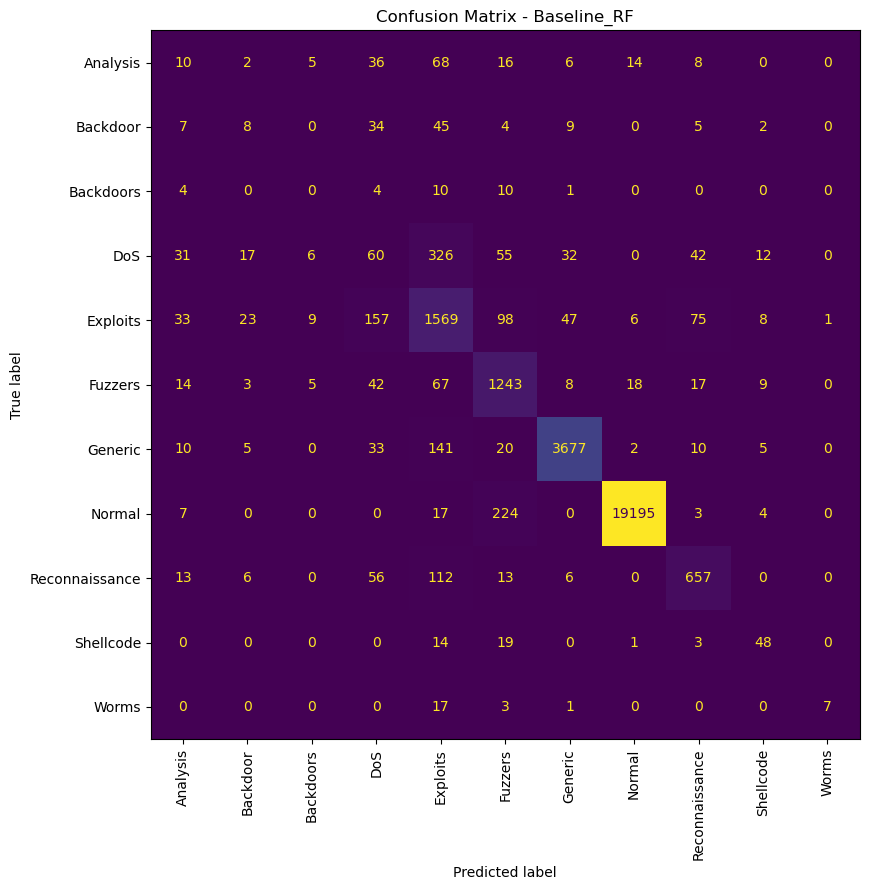


Class_Weighted_RF

                precision    recall  f1-score   support

      Analysis       0.04      0.07      0.05       165
      Backdoor       0.05      0.11      0.07       114
     Backdoors       0.02      0.03      0.02        29
           DoS       0.12      0.10      0.11       581
      Exploits       0.73      0.76      0.75      2026
       Fuzzers       0.76      0.87      0.81      1426
       Generic       0.99      0.94      0.96      3903
        Normal       1.00      0.99      0.99     19450
Reconnaissance       0.83      0.75      0.79       863
     Shellcode       0.53      0.55      0.54        85
         Worms       0.88      0.50      0.64        28

      accuracy                           0.92     28670
     macro avg       0.54      0.52      0.52     28670
  weighted avg       0.93      0.92      0.93     28670



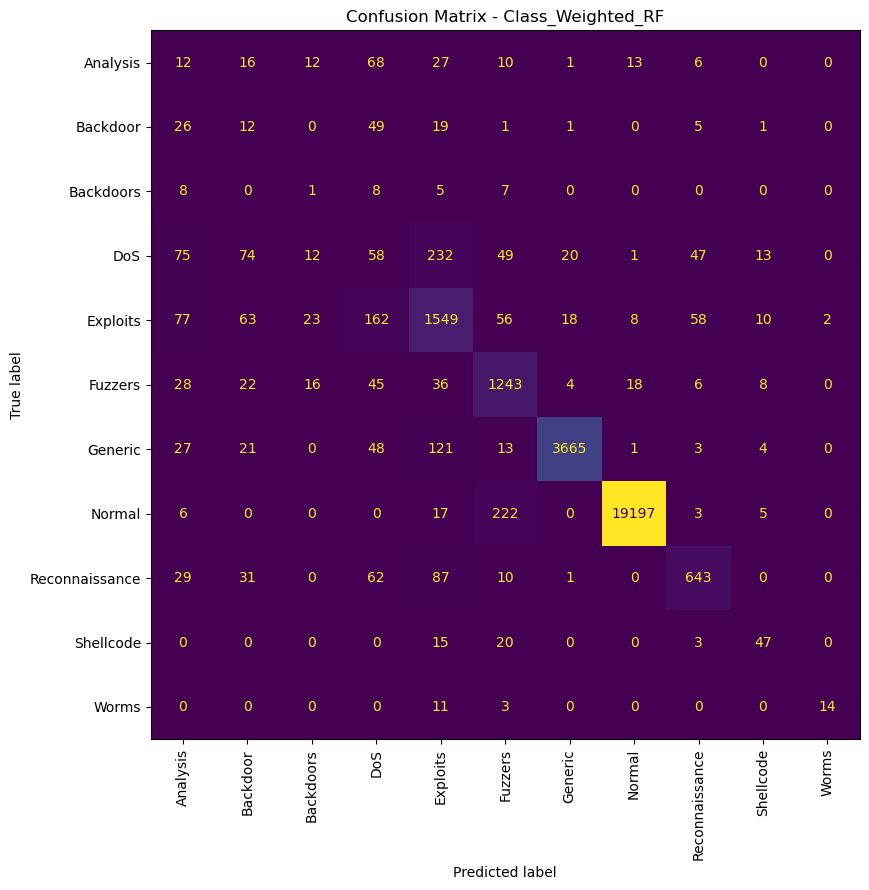


SMOTENC_RF

                precision    recall  f1-score   support

      Analysis       0.06      0.05      0.06       165
      Backdoor       0.13      0.07      0.09       114
     Backdoors       0.00      0.00      0.00        29
           DoS       0.13      0.09      0.11       581
      Exploits       0.66      0.77      0.71      2026
       Fuzzers       0.73      0.87      0.79      1426
       Generic       0.97      0.94      0.95      3903
        Normal       1.00      0.99      0.99     19450
Reconnaissance       0.81      0.76      0.78       863
     Shellcode       0.56      0.59      0.57        85
         Worms       0.60      0.54      0.57        28

      accuracy                           0.92     28670
     macro avg       0.51      0.51      0.51     28670
  weighted avg       0.92      0.92      0.92     28670



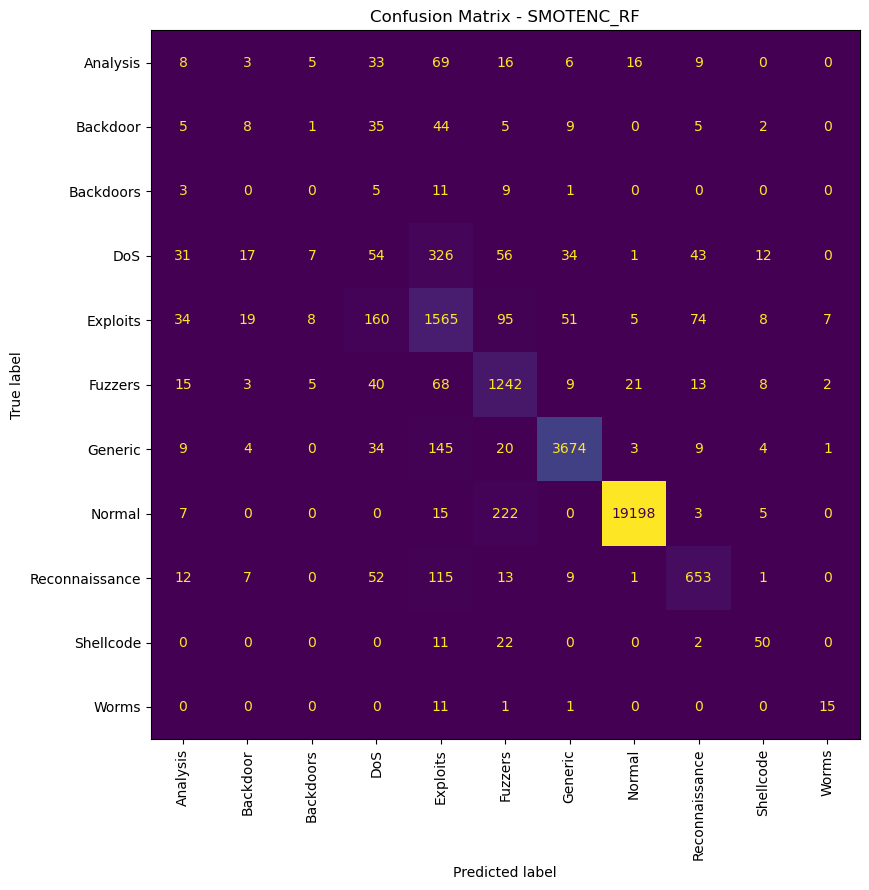


FINAL MODEL COMPARISON
            Model  Accuracy  Worms Precision  Worms Recall  Worms F1-Score  Macro F1-Score
      Baseline_RF    0.9234            0.875        0.2500          0.3889          0.4960
Class_Weighted_RF    0.9223            0.875        0.5000          0.6364          0.5209
       SMOTENC_RF    0.9232            0.600        0.5357          0.5660          0.5113

All reports and confusion matrices saved in:
C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full\experiment_data


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

OUTPUT_DIR = Path(
    r"C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full\experiment_data"
)
OUTPUT_DIR.mkdir(exist_ok=True)

models = {
    "Baseline_RF": pred_baseline,
    "Class_Weighted_RF": pred_weighted,
    "SMOTENC_RF": pred_smote
}

results = []

# Save classification reports and confusion matrices.
for name, predictions in models.items():
    report = classification_report(
        y_test, predictions, zero_division=0
    )

    report_file = OUTPUT_DIR / f"{name}_classification_report.txt"
    report_file.write_text(report, encoding="utf-8")

    print(f"\n{name}\n")
    print(report)

    labels = sorted(pd.Series(y_test).unique())
    cm = confusion_matrix(y_test, predictions, labels=labels)

    fig, ax = plt.subplots(figsize=(11, 9))
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )
    display.plot(
        ax=ax,
        xticks_rotation=90,
        colorbar=False,
        values_format="d"
    )
    ax.set_title(f"Confusion Matrix - {name}")
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{name}_confusion_matrix.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    report_dict = classification_report(
        y_test, predictions,
        output_dict=True,
        zero_division=0
    )
    worms = report_dict.get("Worms", {})

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Worms Precision": worms.get("precision", 0),
        "Worms Recall": worms.get("recall", 0),
        "Worms F1-Score": worms.get("f1-score", 0),
        "Macro F1-Score": report_dict["macro avg"]["f1-score"]
    })

final_results = pd.DataFrame(results).round(4)
final_results.to_csv(
    OUTPUT_DIR / "final_model_results.csv",
    index=False
)

print("\nFINAL MODEL COMPARISON")
print(final_results.to_string(index=False))
print("\nAll reports and confusion matrices saved in:")
print(OUTPUT_DIR)


In [30]:
# Find existing model, dataset, and prediction variables

print("=== MODEL VARIABLES ===")

for name, obj in list(globals().items()):
    try:
        if hasattr(obj, "predict") and callable(obj.predict):
            print(name, "->", type(obj).__name__)
    except Exception:
        pass

print("\n=== DATASET VARIABLES ===")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(obj, (pd.DataFrame, pd.Series)):
        print(
            name,
            "-> shape:",
            obj.shape
        )
    elif name in [
        "X_train", "X_test", "y_train", "y_test",
        "X_train_resampled", "X_train_augmented",
        "X_train_synthetic"
    ]:
        print(name, "->", type(obj).__name__)

=== MODEL VARIABLES ===
RandomForestClassifier -> ABCMeta
ImbPipeline -> ABCMeta
baseline -> Pipeline
Pipeline -> Pipeline
weighted -> Pipeline
smote_rf -> Pipeline

=== DATASET VARIABLES ===
categories -> shape: (40044,)
category -> shape: (50000,)
valid -> shape: (40044,)
summary -> shape: (15, 10)
chunk -> shape: (40044, 49)
counts -> shape: (9,)
selected -> shape: (15, 49)
normal -> shape: (32672, 49)
other_attacks -> shape: (7370, 49)
normal_df -> shape: (100000, 49)
other_attack_df -> shape: (100000, 49)
worms_df -> shape: (174, 49)
working_df -> shape: (143349, 49)
train_df -> shape: (114679, 49)
test_df -> shape: (28670, 49)
worms_train -> shape: (143, 49)
ctgan_train -> shape: (143, 41)
synthetic_worms -> shape: (500, 41)
numeric_df -> shape: (500, 38)
values -> shape: (500,)
synthetic -> shape: (500, 41)
valid_mask -> shape: (500,)
filtered -> shape: (0, 41)
real_worms -> shape: (143, 41)
ctgan_data -> shape: (143, 38)
synthetic_new -> shape: (500, 41)
real -> shape: (143, 41

In [31]:
# Inspect existing model pipelines and synthetic data

print("=== EXISTING MODELS ===")

for name in ["baseline", "weighted", "smote_rf"]:
    if name in globals():
        model = globals()[name]
        print(f"\n{name}: {type(model).__name__}")

        if hasattr(model, "steps"):
            print("Pipeline steps:", [
                (step_name, type(step).__name__)
                for step_name, step in model.steps
            ])

print("\n=== SYNTHETIC DATA SHAPES ===")

for name in [
    "X_train", "y_train", "X_test", "y_test",
    "synthetic_worms", "synthetic_new",
    "real_worms", "worms_train"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {obj.shape}")

print("\n=== TRAINING DATA COLUMNS ===")
print(list(X_train.columns))

print("\n=== SYNTHETIC DATA COLUMNS ===")
if "synthetic_new" in globals():
    print(list(synthetic_new.columns))

=== EXISTING MODELS ===

baseline: Pipeline
Pipeline steps: [('preprocessor', 'ColumnTransformer'), ('classifier', 'RandomForestClassifier')]

weighted: Pipeline
Pipeline steps: [('preprocessor', 'ColumnTransformer'), ('classifier', 'RandomForestClassifier')]

smote_rf: Pipeline
Pipeline steps: [('smote', 'SMOTENC'), ('preprocessor', 'ColumnTransformer'), ('classifier', 'RandomForestClassifier')]

=== SYNTHETIC DATA SHAPES ===
X_train: (114679, 41)
y_train: (114679,)
X_test: (28670, 41)
y_test: (28670,)
synthetic_worms: (500, 41)
synthetic_new: (500, 41)
real_worms: (143, 41)
worms_train: (143, 49)

=== TRAINING DATA COLUMNS ===
['proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd

In [32]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score
)
from IPython.display import display

# =========================================================
# 1. VERIFY THE EXISTING DATA
# =========================================================

assert X_train.columns.equals(X_test.columns), (
    "Training and test features do not match."
)

assert list(synthetic_new.columns) == list(X_train.columns), (
    "Synthetic feature columns or their order do not match X_train."
)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("Real training records:", len(X_train))
print("Synthetic records:", len(synthetic_new))
print("Test records:", len(X_test))


# =========================================================
# 2. PREPARE AUGMENTED TRAINING DATA
# =========================================================

# Convert synthetic features to the same column order.
synthetic_features = synthetic_new[X_train.columns].copy()

# Check for missing or infinite values before training.
synthetic_features = synthetic_features.replace(
    [np.inf, -np.inf], np.nan
)

if synthetic_features.isna().any().any():
    raise ValueError(
        "Synthetic features contain missing/infinite values. "
        "Inspect and handle them before training."
    )

# Synthetic rows represent the Worms class.
# Confirm the exact class label used in your dataset.
print("\nClass labels in y_train:")
print(pd.Series(y_train).value_counts())

print("\nClass labels in y_test:")
print(pd.Series(y_test).value_counts())

print("\nConfirm that the exact Worms label is 'Worms'.")

Real training records: 114679
Synthetic records: 500
Test records: 28670

Class labels in y_train:
attack_cat
Normal            77797
Generic           15321
Exploits           8385
Fuzzers            5826
Reconnaissance     3461
DoS                2203
Analysis            613
Backdoor            419
Shellcode           397
Worms               143
Backdoors           114
Name: count, dtype: int64

Class labels in y_test:
attack_cat
Normal            19450
Generic            3903
Exploits           2026
Fuzzers            1426
Reconnaissance      863
DoS                 581
Analysis            165
Backdoor            114
Shellcode            85
Backdoors            29
Worms                28
Name: count, dtype: int64

Confirm that the exact Worms label is 'Worms'.


In [33]:
import pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score
)
from IPython.display import display

# =========================================================
# 1. CREATE AUGMENTED TRAINING DATA
# =========================================================

synthetic_features = synthetic_new[X_train.columns].copy()

# Assign the confirmed class label to every synthetic row.
synthetic_labels = pd.Series(
    "Worms",
    index=synthetic_features.index,
    name=y_train.name
)

X_augmented = pd.concat(
    [X_train.reset_index(drop=True),
     synthetic_features.reset_index(drop=True)],
    ignore_index=True
)

y_augmented = pd.concat(
    [y_train.reset_index(drop=True),
     synthetic_labels.reset_index(drop=True)],
    ignore_index=True
)

print("Real training records:", len(X_train))
print("Synthetic records added:", len(synthetic_features))
print("Augmented training records:", len(X_augmented))

print("\nAugmented Worms count:")
print((y_augmented == "Worms").sum())


# =========================================================
# 2. TRAIN THE AUGMENTED RANDOM FOREST
# =========================================================

# Reuse the preprocessing and Random Forest configuration
# from your existing baseline pipeline.
augmented_model = clone(baseline)

augmented_model.fit(X_augmented, y_augmented)

print("\nAugmented Random Forest training completed.")


# =========================================================
# 3. EVALUATE BOTH MODELS ON THE SAME TEST SET
# =========================================================

def evaluate_model(model, X_eval, y_eval, experiment_name):

    predictions = model.predict(X_eval)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_eval,
        predictions,
        labels=["Worms"],
        average=None,
        zero_division=0
    )

    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_eval,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "Experiment": experiment_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Worms Precision": precision[0],
        "Worms Recall": recall[0],
        "Worms F1-score": f1[0],
        "Weighted F1-score": weighted_f1,
        "Macro F1-score": f1_score(
            y_eval,
            predictions,
            average="macro",
            zero_division=0
        )
    }


real_result = evaluate_model(
    baseline,
    X_test,
    y_test,
    "Real-only Random Forest"
)

augmented_result = evaluate_model(
    augmented_model,
    X_test,
    y_test,
    "Real + Synthetic Random Forest"
)

comparison_df = pd.DataFrame([
    real_result,
    augmented_result
])

print("\nREAL vs AUGMENTED RESULTS")
display(comparison_df.round(4))


# =========================================================
# 4. SHOW METRIC CHANGES
# =========================================================

metric_columns = [
    "Accuracy",
    "Worms Precision",
    "Worms Recall",
    "Worms F1-score",
    "Weighted F1-score",
    "Macro F1-score"
]

changes = (
    comparison_df.iloc[1][metric_columns].astype(float)
    - comparison_df.iloc[0][metric_columns].astype(float)
)

change_df = pd.DataFrame({
    "Metric": metric_columns,
    "Change": changes.values
})

print("\nCHANGE AFTER SYNTHETIC AUGMENTATION")
display(change_df.round(4))


# =========================================================
# 5. SAVE RESULTS FOR THE STREAMLIT DASHBOARD
# =========================================================

output_dir = Path("experiment_data")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "real_vs_augmented_comparison.csv"

comparison_df.to_csv(output_file, index=False)

print("\nSaved comparison to:")
print(output_file.resolve())

Real training records: 114679
Synthetic records added: 500
Augmented training records: 115179

Augmented Worms count:
643

Augmented Random Forest training completed.

REAL vs AUGMENTED RESULTS


,Experiment,Accuracy,Worms Precision,Worms Recall,Worms F1-score,Weighted F1-score,Macro F1-score
0,Real-only Random Forest,0.9234,0.8750,0.2500,0.3889,0.9219,0.4960
1,Real + Synthetic Random Forest,0.9237,0.7692,0.3571,0.4878,0.9220,0.5043



CHANGE AFTER SYNTHETIC AUGMENTATION


,Metric,Change
0,Accuracy,0.0003
1,Worms Precision,-0.1058
2,Worms Recall,0.1071
3,Worms F1-score,0.0989
4,Weighted F1-score,0.0001
5,Macro F1-score,0.0083



Saved comparison to:
C:\Users\HP\experiment_data\real_vs_augmented_comparison.csv


In [34]:
from pathlib import Path

output_file = Path.home() / "Desktop" / "In-House project" / "UNSW-NB15_Full" / "experiment_data" / "real_vs_augmented_comparison.csv"

output_file.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(output_file, index=False)

print("Saved successfully:", output_file)
print("File exists:", output_file.exists())

Saved successfully: C:\Users\HP\Desktop\In-House project\UNSW-NB15_Full\experiment_data\real_vs_augmented_comparison.csv
File exists: True
